In [4]:
# Cell 1: Environment & Kaggle Paths Setup
import os, sys, re, random
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

# Auto-install MNE if missing
try:
    import mne
except ImportError:
    !pip install -q mne
    import mne

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training Device:", DEVICE)

# Kaggle Directory Setup
INPUT_ROOT = Path("/kaggle/input")
WORKING_DIR = Path("/kaggle/working")
CKPT_DIR = WORKING_DIR / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# Recursively locate all EDF files under /kaggle/input 
all_edfs = [p for p in INPUT_ROOT.rglob("*") if p.suffix.lower() == ".edf"] if INPUT_ROOT.exists() else []

if all_edfs:
    MUMTAZ_DIR = all_edfs[0].parent
    print(f"Auto-located {len(all_edfs)} EDF files in: {MUMTAZ_DIR}")
else:
    # Local fallback
    MUMTAZ_DIR = Path("data/MUMTAZ")
    if not MUMTAZ_DIR.exists():
        MUMTAZ_DIR = Path("/content/drive/MyDrive/Data/MUMTAZ")
    print(f"Fallback MUMTAZ Directory: {MUMTAZ_DIR}")

print(f"Checkpoints Directory : {CKPT_DIR}")

Training Device: cuda
Auto-located 181 EDF files in: /kaggle/input/datasets/ravidujeewantha/mumtaz/MUMTAZ
Checkpoints Directory : /kaggle/working/checkpoints


In [5]:
# Cell 2: Core SNN Engine 
from scipy.signal import butter, sosfiltfilt
from torch.autograd import Function

class SuperSpike(Function):
    @staticmethod
    def forward(ctx, u):
        ctx.save_for_backward(u)
        return (u > 0.0).float()
    @staticmethod
    def backward(ctx, grad_output):
        (u,) = ctx.saved_tensors
        return grad_output / (1.0 + 10.0 * torch.abs(u)) ** 2

superspike = SuperSpike.apply

class ALIFNeuron(nn.Module):
    def __init__(self, size, beta_init=0.9, v_th_init=1.0, beta_ad_init=0.5):
        super().__init__()
        self.beta = nn.Parameter(torch.full((size,), beta_init))
        self.v_th_base = nn.Parameter(torch.full((size,), v_th_init))
        self.beta_ad = nn.Parameter(torch.full((size,), beta_ad_init))

    def init_state(self, b, device):
        return torch.zeros(b, len(self.beta), device=device), torch.zeros(b, len(self.beta), device=device)

    def step(self, current, state):
        u, a = state
        theta = self.v_th_base.clamp(min=0.1) + self.beta_ad.clamp(0.01, 0.99) * a
        s = superspike(u - theta)
        u_next = self.beta.clamp(0.1, 0.99) * u * (1.0 - s) + current
        a_next = self.beta_ad.clamp(0.01, 0.99) * a + s
        return s, (u_next, a_next), u_next

class STDPLayer(nn.Module):
    def __init__(self, size, lr=0.001):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(size, size).uniform_(-0.1, 0.1))
        self.lr = lr

    def step(self, spikes, trace):
        trace = 0.9 * trace + spikes
        dw = self.lr * (torch.bmm(spikes.unsqueeze(2), trace.unsqueeze(1)) - torch.bmm(trace.unsqueeze(2), spikes.unsqueeze(1))).mean(0)
        self.weight.data.clamp_(-1.0, 1.0).add_(dw.clamp(-0.01, 0.01))
        return spikes, trace

class GlobalSNNBackbone(nn.Module):
    def __init__(self, n_input_channels=38, reservoir_size=128, ablation_mode="full_engine", n_classes=2):
        super().__init__()
        self.n_input_channels = n_input_channels
        self.reservoir_size = reservoir_size
        self.use_ip = "full_engine" in ablation_mode
        self.dt_ms = 4.0

        self.input_proj = nn.Linear(n_input_channels, reservoir_size)
        rec = torch.empty(reservoir_size, reservoir_size).normal_(0, 1.0 / np.sqrt(reservoir_size))
        self.w_rec = nn.Parameter(rec * (0.95 / max(1e-6, torch.abs(torch.linalg.eigvals(rec)).max().item())))
        self.neuron = ALIFNeuron(reservoir_size)
        self.stdp_layer = STDPLayer(reservoir_size) if "stdp" in ablation_mode or "full_engine" in ablation_mode else None
        self.feature_proj = nn.Linear(reservoir_size, 256)
        self.classifier = nn.Linear(256, n_classes)
        self.readout_vth = nn.Parameter(torch.ones(n_classes))

    def forward_classify(self, spikes):
        b, t, _ = spikes.shape
        state = self.neuron.init_state(b, spikes.device)
        s_prev = torch.zeros(b, self.reservoir_size, device=spikes.device)
        feed = self.input_proj(spikes)
        res_spikes = []
        for step in range(t):
            cur = feed[:, step] + torch.matmul(s_prev, self.w_rec.t())
            s_out, state, _ = self.neuron.step(cur, state)
            s_prev = s_out
            res_spikes.append(s_out)
        res_spk_t = torch.stack(res_spikes, dim=1)
        feat = self.feature_proj(res_spk_t)
        logits = self.classifier(feat.mean(dim=1))
        preds = logits.argmax(dim=-1)
        aux = {
            "res_spikes": res_spk_t,
            "total_synops": int(res_spk_t.sum().item() * self.reservoir_size),
            "sparsity": 1.0 - (res_spk_t.sum().item() / max(1, res_spk_t.numel()))
        }
        return logits, preds, aux

    def fit_stdp(self, spikes):
        if self.stdp_layer is None:
            return
        b, t, _ = spikes.shape
        trace = torch.zeros(b, self.reservoir_size, device=spikes.device)
        feed = self.input_proj(spikes)
        state = self.neuron.init_state(b, spikes.device)
        s_prev = torch.zeros(b, self.reservoir_size, device=spikes.device)
        with torch.no_grad():
            for step in range(t):
                cur = feed[:, step] + torch.matmul(s_prev, self.w_rec.t())
                s, state, _ = self.neuron.step(cur, state)
                s_prev = s
                _, trace = self.stdp_layer.step(s, trace)

    def apply_intrinsic_plasticity(self, spikes, win_dur):
        if not self.use_ip:
            return
        with torch.no_grad():
            hz = spikes.sum(dim=(0, 1)) / max(1e-5, spikes.shape[0] * win_dur)
            delta = torch.where(hz > 35.0, 0.005, torch.where(hz < 10.0, -0.005, 0.0))
            self.neuron.v_th_base.data.add_(delta).clamp_(min=0.1)

    def constrain_parameters(self):
        self.neuron.v_th_base.data.clamp_(min=0.1)
        self.readout_vth.data.clamp_(min=0.1)

In [7]:
# Cell 3: Preprocessing & Adaptive TBR Encoding
MUMTAZ_CHANNELS = ("Fp1", "F3", "C3", "P3", "O1", "F7", "T3", "T5", "Fz", "Cz", "Pz", "Fp2", "F4", "C4", "P4", "O2", "F8", "T4", "T6")
CACHE_FILE = CKPT_DIR / "mumtaz_encoded_EC.pt"

def make_windows(eeg: np.ndarray, fs: float, window_sec: float = 2.0) -> np.ndarray:
    win = int(round(window_sec * fs))
    n_samples = eeg.shape[-1]
    if n_samples < win:
        return np.empty((0, eeg.shape[0], win), dtype=eeg.dtype)
    starts = range(0, n_samples - win + 1, win)
    return np.stack([eeg[:, s : s + win] for s in starts])

def tbr_encode_dual_binary(windows: np.ndarray, thresholds: np.ndarray) -> torch.Tensor:
    diffs = windows[:, :, 1:] - windows[:, :, :-1]
    th = thresholds[None, :, None]
    up = (diffs > th).astype(np.float32)
    down = (diffs < -th).astype(np.float32)
    up = np.pad(up, ((0, 0), (0, 0), (1, 0)))
    down = np.pad(down, ((0, 0), (0, 0), (1, 0)))
    up = np.transpose(up, (0, 2, 1))
    down = np.transpose(down, (0, 2, 1))
    return torch.from_numpy(np.concatenate((up, down), axis=-1)).float()

# Invalidate cache if previous run saved 0 subjects
cached = None
if CACHE_FILE.exists():
    cached = torch.load(CACHE_FILE, weights_only=False)
    if len(cached.get("subjects", [])) == 0:
        print("--> Previous cache had 0 subjects. Clearing cache...")
        CACHE_FILE.unlink(missing_ok=True)
        cached = None
    else:
        print(f"--> Loading pre-encoded dataset from cache: {CACHE_FILE.name}")

if cached is None:
    all_edfs = [p for p in MUMTAZ_DIR.rglob("*") if p.suffix.lower() == ".edf"] if MUMTAZ_DIR.exists() else []
    if not all_edfs and Path("/kaggle/input").exists():
        all_edfs = [p for p in Path("/kaggle/input").rglob("*") if p.suffix.lower() == ".edf"]
    
    ec_files = [p for p in all_edfs if "EC" in p.name.upper() and "TASK" not in p.name.upper()]
    print(f"Found {len(all_edfs)} total EDFs, {len(ec_files)} Eyes-Closed (EC) files.")

    subjects, labels, eval_spikes, all_spikes = [], {}, {}, {}

    for p in ec_files:
        stem = p.stem
        m_mdd = re.search(r"MDD\s*S\s*(\d+)", stem, re.I)
        m_hc = re.search(r"(?:^|\D)H\s*S\s*(\d+)", stem, re.I)
        if m_mdd:
            sid = f"MDD_S{int(m_mdd.group(1)):02d}"
            lbl = 1
        elif m_hc:
            sid = f"HC_S{int(m_hc.group(1)):02d}"
            lbl = 0
        else:
            continue

        if sid in labels:
            continue

        raw = mne.io.read_raw_edf(str(p), preload=True, verbose=False)
        picks = [ch for ch in raw.ch_names if any(std in ch for std in MUMTAZ_CHANNELS) and not any(x in ch for x in ["A2", "23A", "24A"])]
        if len(picks) != 19:
            continue

        raw.pick(picks[:19])
        fs, d = float(raw.info["sfreq"]), raw.get_data().astype(np.float64)
        sos = butter(4, [0.5, 45.0], btype="bandpass", fs=fs, output="sos")
        filt = sosfiltfilt(sos, d, axis=-1)
        windows = make_windows(filt, fs=fs, window_sec=2.0)
        if len(windows) < 10:
            continue

        # 20% calibration split
        n_cal = max(1, int(round(len(windows) * 0.2)))
        cal_win, eval_win = windows[:n_cal], windows[n_cal:]
        mean = cal_win.mean(axis=(0, 2), keepdims=True)
        std = cal_win.std(axis=(0, 2), keepdims=True) + 1e-8
        cal_scaled = (cal_win - mean) / std
        eval_scaled = (eval_win - mean) / std

        # C1 Adaptive TBR thresholds
        diffs = cal_scaled[:, :, 1:] - cal_scaled[:, :, :-1]
        thresholds = diffs.mean(axis=(0, 2)) + 1.0 * diffs.std(axis=(0, 2))
        thresholds = np.maximum(thresholds, 1e-6)

        cal_spk = tbr_encode_dual_binary(cal_scaled, thresholds)
        eval_spk = tbr_encode_dual_binary(eval_scaled, thresholds)

        subjects.append(sid)
        labels[sid] = lbl
        eval_spikes[sid] = eval_spk
        all_spikes[sid] = torch.cat((cal_spk, eval_spk), dim=0)

    if len(subjects) == 0:
        raise RuntimeError(f"Error: 0 subjects encoded from {len(ec_files)} EC files.")

    cached = {"subjects": sorted(subjects), "labels": labels, "eval_spikes": eval_spikes, "all_spikes": all_spikes}
    torch.save(cached, CACHE_FILE)
    print(f"--> Successfully encoded and cached {len(subjects)} subjects to {CACHE_FILE.name}")

subjects, labels = cached["subjects"], cached["labels"]
eval_spikes, all_spikes = cached["eval_spikes"], cached["all_spikes"]
print(f"Dataset Ready: {len(subjects)} subjects ({sum(labels.values())} MDD, {len(subjects)-sum(labels.values())} Healthy)")

Found 181 total EDFs, 58 Eyes-Closed (EC) files.
--> Successfully encoded and cached 58 subjects to mumtaz_encoded_EC.pt
Dataset Ready: 58 subjects (30 MDD, 28 Healthy)


In [8]:
# Cell 4: Experiment Config & 5-Fold Stratification
SEED, RESERVOIR_SIZE, LR, EPOCHS, BATCH_SIZE = 42, 128, 0.001, 10, 16
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(subjects, [labels[s] for s in subjects]))
print(f"Configured 5-Fold Stratified Cross-Validation on {len(subjects)} subjects.")

Configured 5-Fold Stratified Cross-Validation on 58 subjects.


In [9]:
# Cell 5: 5-Fold Training Loop with Kaggle Checkpointing
mode = "full_engine"
print(f"Starting Benchmark: {mode}")
fold_metrics, best_mode_f1, best_mode_model = [], -1.0, None

for f_idx, (train_idx, test_idx) in enumerate(folds, 1):
    comp_file = CKPT_DIR / f"{mode}_fold_{f_idx}_completed.pt"
    ckpt_file = CKPT_DIR / f"{mode}_fold_{f_idx}_checkpoint.pt"

    # Skip if already completed
    if comp_file.exists():
        saved = torch.load(comp_file, map_location=DEVICE, weights_only=False)
        m = saved["metrics"]
        fold_metrics.append(m)
        print(f"Fold {f_idx}/5 [ALREADY COMPLETED] -> Acc: {m['acc']*100:.2f}%, F1: {m['f1']:.3f}")
        if m["f1"] > best_mode_f1:
            best_mode_f1 = m["f1"]
            best_mode_model = GlobalSNNBackbone(n_input_channels=38, reservoir_size=RESERVOIR_SIZE, ablation_mode=mode).to(DEVICE)
            best_mode_model.load_state_dict(saved["model_state_dict"])
        continue

    print(f"\n Training Fold {f_idx}/5 ")
    train_s, test_s = [subjects[i] for i in train_idx], [subjects[i] for i in test_idx]
    x_train = torch.cat([all_spikes[s] for s in train_s], dim=0).to(DEVICE)
    y_train = torch.tensor([labels[s] for s in train_s for _ in range(len(all_spikes[s]))], dtype=torch.long, device=DEVICE)
    x_test = torch.cat([eval_spikes[s] for s in test_s], dim=0).to(DEVICE)
    y_test = torch.tensor([labels[s] for s in test_s for _ in range(len(eval_spikes[s]))], dtype=torch.long, device=DEVICE)

    backbone = GlobalSNNBackbone(n_input_channels=38, reservoir_size=RESERVOIR_SIZE, ablation_mode=mode).to(DEVICE)
    optimizer = torch.optim.Adam(backbone.parameters(), lr=LR, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()
    start_epoch = 1

    # Resume mid-fold checkpoint if exists
    if ckpt_file.exists():
        ckpt = torch.load(ckpt_file, map_location=DEVICE, weights_only=False)
        backbone.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        start_epoch = ckpt["epoch"] + 1
        print(f"Resuming Fold {f_idx} from Epoch {start_epoch}/{EPOCHS}")
    elif backbone.stdp_layer is not None:
        backbone.fit_stdp(x_train[:128])

    # Epoch Loop
    for epoch in range(start_epoch, EPOCHS + 1):
        backbone.train()
        perm = torch.randperm(len(x_train), device=DEVICE)
        loss_sum, batches = 0.0, 0
        for b in range(0, len(x_train), BATCH_SIZE):
            bx, by = x_train[perm[b:b+BATCH_SIZE]], y_train[perm[b:b+BATCH_SIZE]]
            optimizer.zero_grad()
            logits, _, aux = backbone.forward_classify(bx)
            loss = criterion(logits, by)
            loss.backward(); optimizer.step(); backbone.constrain_parameters()
            loss_sum += loss.item(); batches += 1
            if backbone.use_ip:
                backbone.apply_intrinsic_plasticity(aux["res_spikes"], bx.shape[1] * (backbone.dt_ms / 1000.0))

        # Val per epoch
        backbone.eval()
        preds_l = []
        with torch.no_grad():
            for b in range(0, len(x_test), BATCH_SIZE):
                _, p, _ = backbone.forward_classify(x_test[b:b+BATCH_SIZE])
                preds_l.append(p.cpu())
        y_p, y_t = torch.cat(preds_l).numpy(), y_test.cpu().numpy()
        ep_acc = accuracy_score(y_t, y_p)
        ep_f1 = f1_score(y_t, y_p, average="macro", zero_division=0)
        print(f"Epoch {epoch:2d}/{EPOCHS} | Loss: {loss_sum/batches:.4f} | Val Acc: {ep_acc*100:.2f}% | Val F1: {ep_f1:.3f}")

        torch.save({"fold": f_idx, "epoch": epoch, "model_state_dict": backbone.state_dict(), "optimizer_state_dict": optimizer.state_dict()}, ckpt_file)

    # Final Fold Evaluation & Save Completion
    backbone.eval()
    preds_l, synops_tot, sp_tot = [], 0, 0.0
    with torch.no_grad():
        for b in range(0, len(x_test), BATCH_SIZE):
            bx = x_test[b:b+BATCH_SIZE]
            _, p, aux = backbone.forward_classify(bx)
            preds_l.append(p.cpu())
            synops_tot += aux["total_synops"]
            sp_tot += aux["sparsity"] * len(bx)
    y_p, y_t = torch.cat(preds_l).numpy(), y_test.cpu().numpy()
    m = {
        "acc": accuracy_score(y_t, y_p),
        "rec": recall_score(y_t, y_p, average="binary", zero_division=0),
        "f1": f1_score(y_t, y_p, average="macro", zero_division=0),
        "synops": synops_tot / max(1, len(x_test)),
        "sparsity": sp_tot / max(1, len(x_test)),
        "cm": confusion_matrix(y_t, y_p).tolist()
    }
    fold_metrics.append(m)
    print(f"--> Fold {f_idx} Final -> Acc: {m['acc']*100:.2f}%, F1: {m['f1']:.3f}")
    if m["f1"] > best_mode_f1:
        best_mode_f1, best_mode_model = m["f1"], backbone

    torch.save({"fold": f_idx, "model_state_dict": backbone.state_dict(), "metrics": m, "completed": True}, comp_file)
    if ckpt_file.exists(): ckpt_file.unlink()

# Save Overall Best Model across Folds
best_path = CKPT_DIR / f"global_backbone_mumtaz_{mode}_best.pt"
if best_mode_model is not None:
    torch.save(best_mode_model.state_dict(), best_path)
    print(f"\nSaved overall best model to: {best_path}")

Starting Benchmark: full_engine

 Training Fold 1/5 
Epoch  1/10 | Loss: 0.4685 | Val Acc: 73.07% | Val F1: 0.711
Epoch  2/10 | Loss: 0.3094 | Val Acc: 84.97% | Val F1: 0.848
Epoch  3/10 | Loss: 0.2842 | Val Acc: 83.16% | Val F1: 0.830
Epoch  4/10 | Loss: 0.2471 | Val Acc: 83.51% | Val F1: 0.835
Epoch  5/10 | Loss: 0.2162 | Val Acc: 82.81% | Val F1: 0.826
Epoch  6/10 | Loss: 0.2161 | Val Acc: 84.55% | Val F1: 0.845
Epoch  7/10 | Loss: 0.1906 | Val Acc: 77.17% | Val F1: 0.764
Epoch  8/10 | Loss: 0.1669 | Val Acc: 83.58% | Val F1: 0.836
Epoch  9/10 | Loss: 0.1554 | Val Acc: 84.76% | Val F1: 0.847
Epoch 10/10 | Loss: 0.1379 | Val Acc: 82.32% | Val F1: 0.822
--> Fold 1 Final -> Acc: 82.32%, F1: 0.822

 Training Fold 2/5 
Epoch  1/10 | Loss: 0.4488 | Val Acc: 78.57% | Val F1: 0.785
Epoch  2/10 | Loss: 0.3063 | Val Acc: 78.43% | Val F1: 0.778
Epoch  3/10 | Loss: 0.2617 | Val Acc: 78.36% | Val F1: 0.783
Epoch  4/10 | Loss: 0.2215 | Val Acc: 83.31% | Val F1: 0.831
Epoch  5/10 | Loss: 0.2017 | 

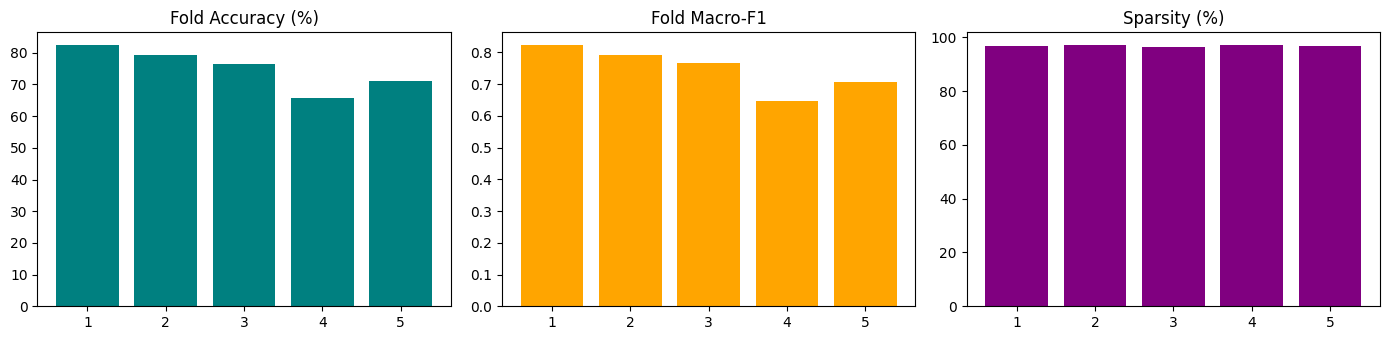

In [10]:
# Summary Plot
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].bar(range(1, 6), [f['acc']*100 for f in fold_metrics], color='teal'); ax[0].set_title('Fold Accuracy (%)')
ax[1].bar(range(1, 6), [f['f1'] for f in fold_metrics], color='orange'); ax[1].set_title('Fold Macro-F1')
ax[2].bar(range(1, 6), [f['sparsity']*100 for f in fold_metrics], color='purple'); ax[2].set_title('Sparsity (%)')
plt.tight_layout(); plt.show()

In [11]:
from IPython.display import FileLink
FileLink('checkpoints/global_backbone_mumtaz_full_engine_best.pt')

/kaggle/working/checkpoints/global_backbone_mumtaz_full_engine_best.pt